In [4]:
from prey_predator_sim.population import Population

In [80]:
# Klasy testowe do sprawdzenia dzialania klasy Population
# .survives decyduje o przezyciu osobnika

class TestPrey:
    def __init__(self):
        self.alive = True
        self.survives = True

    def kill(self):
        if not self.survives:
            self.alive = False


class TestPredator:
    def __init__(self):
        self.alive = True
        self.survives = True

    def kill(self):
        if not self.survives:
            self.alive = False

In [81]:
population = Population({
    TestPrey: 5,
    TestPredator: 3,
})

print("Liczebności:", population.n)
print("Historia:", population.history)

Liczebności: {<class '__main__.TestPrey'>: 5, <class '__main__.TestPredator'>: 3}
Historia: [8]


In [78]:
for creature in population._instances:
    if type(creature) == TestPrey:
        creature.survives = False

population.natural_selection()

print("Po selekcji:", population.n)
print("Historia:", population.history)

Po selekcji: {<class '__main__.TestPrey'>: 0, <class '__main__.TestPredator'>: 3}
Historia: [8, 3]


Końcowe liczebności: {<class '__main__.TestPrey'>: 0, <class '__main__.TestPredator'>: 0}
Historia: [8, 3, 0]


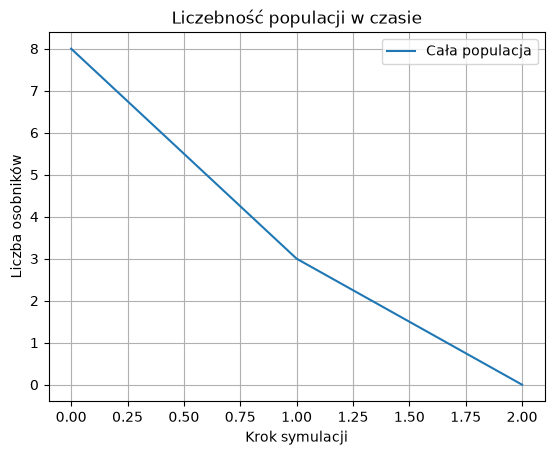

In [79]:
for creature in population._instances:
    creature.survives = False

population.natural_selection()

print("Końcowe liczebności:", population.n)
print("Historia:", population.history)

population.plot_history()

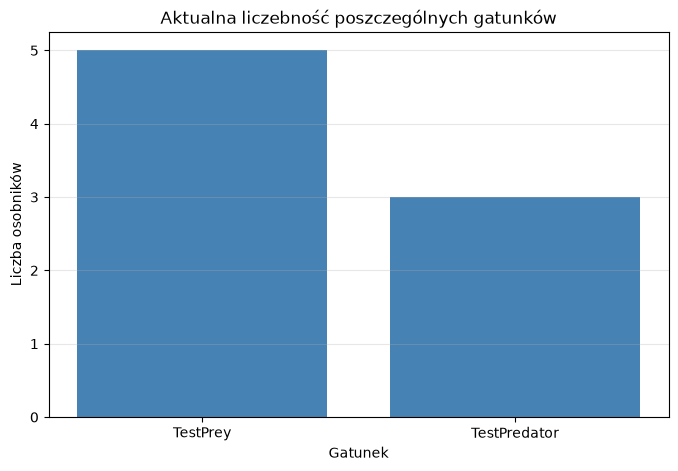

In [82]:
import matplotlib.pyplot as plt

counts = population.n

names = []
numbers = []

for species, count in counts.items():
    names.append(species.__name__)
    numbers.append(count)

plt.figure(figsize=(8, 5))

plt.bar(names, numbers, color="steelblue")

plt.xlabel("Gatunek")
plt.ylabel("Liczba osobników")
plt.title("Aktualna liczebność poszczególnych gatunków")
plt.grid(axis="y", alpha=0.3)

plt.show()

# Ten wykres wymaga ponownego uzycia trzeciej komorki

In [69]:
population = Population({
    TestPrey: 30,
    TestPredator: 20,
})

species_history = {}

# Zapisujemy liczebności początkowe.
for species, count in population.n.items():
    species_history[species] = [count]

In [70]:
import random

random.seed(42)

for step in range(15):
    for creature in population._instances:
        creature.survives = random.random() >= 0.15

    population.natural_selection()

    # Dopisujemy bieżącą liczebność każdego gatunku.
    for species, count in population.n.items():
        species_history[species].append(count)

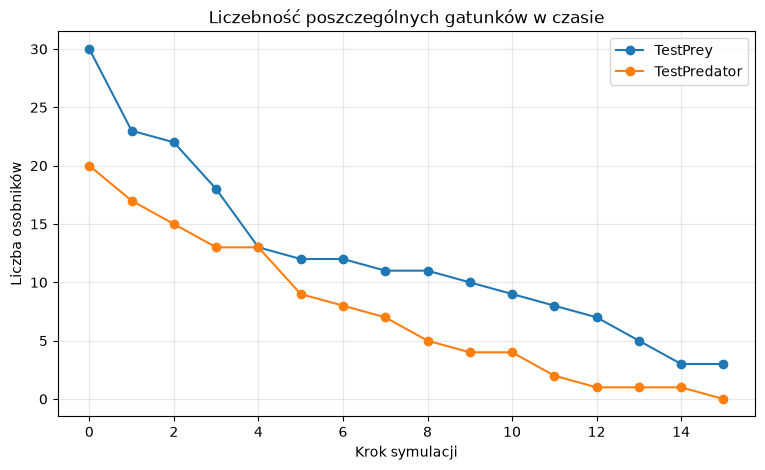

In [71]:
plt.figure(figsize=(9, 5))

for species, history in species_history.items():
    plt.plot(
        range(len(history)),
        history,
        marker="o",
        label=species.__name__
    )

plt.xlabel("Krok symulacji")
plt.ylabel("Liczba osobników")
plt.title("Liczebność poszczególnych gatunków w czasie")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

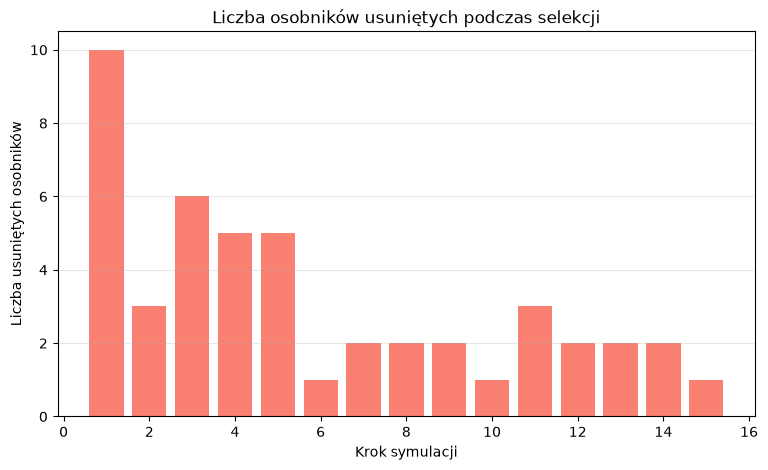

In [72]:
removed = []

for step in range(1, len(population.history)):
    previous_count = population.history[step - 1]
    current_count = population.history[step]

    removed.append(previous_count - current_count)

plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(population.history)),
    removed,
    color="salmon"
)

plt.xlabel("Krok symulacji")
plt.ylabel("Liczba usuniętych osobników")
plt.title("Liczba osobników usuniętych podczas selekcji")
plt.grid(axis="y", alpha=0.3)

plt.show()